In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ACTUALS_PATH = DATA_DIR / "fuelhh_january_2026.csv"
FORECASTS_PATH = DATA_DIR / "windfor_january_2026.csv"

actuals_raw = pd.read_csv(ACTUALS_PATH)
forecasts_raw = pd.read_csv(FORECASTS_PATH)

print("Actuals shape:", actuals_raw.shape)
print("Forecasts shape:", forecasts_raw.shape)

Actuals shape: (1488, 7)
Forecasts shape: (17536, 4)


In [12]:
for name, df in [
    ("FUELHH actuals", actuals_raw),
    ("WINDFOR forecasts", forecasts_raw),
]:
    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
    display(df.head())
    display(df.tail())
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
        "unique_values": df.nunique(),
    }))
    display(df.describe(include="all").T)


FUELHH actuals


,dataset,publishTime,startTime,settlementDate,settlementPeriod,fuelType,generation
0,FUELHH,2026-02-01T00:00:00Z,2026-01-31 23:30:00+00:00,2026-01-31,48,WIND,8849
1,FUELHH,2026-01-31T23:30:00Z,2026-01-31 23:00:00+00:00,2026-01-31,47,WIND,9130
2,FUELHH,2026-01-31T23:00:00Z,2026-01-31 22:30:00+00:00,2026-01-31,46,WIND,9320
3,FUELHH,2026-01-31T22:30:00Z,2026-01-31 22:00:00+00:00,2026-01-31,45,WIND,9475
4,FUELHH,2026-01-31T22:00:00Z,2026-01-31 21:30:00+00:00,2026-01-31,44,WIND,9315


,dataset,publishTime,startTime,settlementDate,settlementPeriod,fuelType,generation
1483,FUELHH,2026-01-01T02:30:00Z,2026-01-01 02:00:00+00:00,2026-01-01,5,WIND,14185
1484,FUELHH,2026-01-01T02:00:00Z,2026-01-01 01:30:00+00:00,2026-01-01,4,WIND,14077
1485,FUELHH,2026-01-01T01:30:00Z,2026-01-01 01:00:00+00:00,2026-01-01,3,WIND,14036
1486,FUELHH,2026-01-01T01:00:00Z,2026-01-01 00:30:00+00:00,2026-01-01,2,WIND,13873
1487,FUELHH,2026-01-01T00:30:00Z,2026-01-01 00:00:00+00:00,2026-01-01,1,WIND,13756


,dtype,missing_count,missing_percent,unique_values
dataset,str,0,0.0,1
publishTime,str,0,0.0,1486
startTime,str,0,0.0,1488
settlementDate,str,0,0.0,31
settlementPeriod,int64,0,0.0,48
fuelType,str,0,0.0,1
generation,int64,0,0.0,1406


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
dataset,1488,1,FUELHH,1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
publishTime,1488,1486,2026-01-15T12:26:00Z,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
startTime,1488,1488,2026-01-31 23:30:00+00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
settlementDate,1488,31,2026-01-31,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
settlementPeriod,1488.0,NaN,NaN,NaN,24.5,13.86,1.0,12.75,24.5,36.25,48.0
fuelType,1488,1,WIND,1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
generation,1488.0,NaN,NaN,NaN,11580.74,4156.22,1695.0,8197.5,12141.0,15265.5,17805.0



WINDFOR forecasts


,dataset,publishTime,startTime,generation
0,WINDFOR,2026-01-31 22:30:00+00:00,2026-01-30 21:00:00+00:00,17683
1,WINDFOR,2026-01-31 22:30:00+00:00,2026-01-30 22:00:00+00:00,17313
2,WINDFOR,2026-01-31 22:30:00+00:00,2026-01-30 23:00:00+00:00,17030
3,WINDFOR,2026-01-31 22:30:00+00:00,2026-01-31 00:00:00+00:00,16403
4,WINDFOR,2026-01-31 22:30:00+00:00,2026-01-31 01:00:00+00:00,15966


,dataset,publishTime,startTime,generation
17531,WINDFOR,2026-01-01 02:30:00+00:00,2026-01-03 17:00:00+00:00,14762
17532,WINDFOR,2026-01-01 02:30:00+00:00,2026-01-03 18:00:00+00:00,14679
17533,WINDFOR,2026-01-01 02:30:00+00:00,2026-01-03 19:00:00+00:00,14595
17534,WINDFOR,2026-01-01 02:30:00+00:00,2026-01-03 20:00:00+00:00,14376
17535,WINDFOR,2026-01-01 02:30:00+00:00,2026-01-03 21:00:00+00:00,14306


,dtype,missing_count,missing_percent,unique_values
dataset,str,0,0.0,1
publishTime,str,0,0.0,248
startTime,str,0,0.0,744
generation,int64,0,0.0,9266


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
dataset,17536,1,WINDFOR,17536,NaN,NaN,NaN,NaN,NaN,NaN,NaN
publishTime,17536,248,2026-01-29 22:30:00+00:00,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
startTime,17536,744,2026-01-30 21:00:00+00:00,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
generation,17536.0,NaN,NaN,NaN,13167.61,4871.96,2250.0,9107.5,13030.0,17726.0,21353.0


In [13]:
required_actual_cols = {"startTime", "generation", "fuelType"}
required_forecast_cols = {"startTime", "publishTime", "generation"}

assert required_actual_cols.issubset(actuals_raw.columns), (
    f"Missing actual columns: {required_actual_cols - set(actuals_raw.columns)}"
)
assert required_forecast_cols.issubset(forecasts_raw.columns), (
    f"Missing forecast columns: {required_forecast_cols - set(forecasts_raw.columns)}"
)

actuals = actuals_raw.copy()
forecasts = forecasts_raw.copy()

actuals["startTime"] = pd.to_datetime(
    actuals["startTime"], utc=True, errors="coerce"
)

forecasts["startTime"] = pd.to_datetime(
    forecasts["startTime"], utc=True, errors="coerce"
)
forecasts["publishTime"] = pd.to_datetime(
    forecasts["publishTime"], utc=True, errors="coerce"
)

actuals["generation"] = pd.to_numeric(
    actuals["generation"], errors="coerce"
)
forecasts["generation"] = pd.to_numeric(
    forecasts["generation"], errors="coerce"
)

display(actuals.dtypes.to_frame("actuals_dtype"))
display(forecasts.dtypes.to_frame("forecasts_dtype"))

,actuals_dtype
dataset,str
publishTime,str
startTime,"datetime64[us, UTC]"
settlementDate,str
settlementPeriod,int64
fuelType,str
generation,int64


,forecasts_dtype
dataset,str
publishTime,"datetime64[us, UTC]"
startTime,"datetime64[us, UTC]"
generation,int64


In [14]:
quality_checks = {
    "actuals_rows": len(actuals),
    "actuals_duplicate_delivery_times": actuals["startTime"].duplicated().sum(),
    "actuals_invalid_timestamps": actuals["startTime"].isna().sum(),
    "actuals_invalid_generation": actuals["generation"].isna().sum(),
    "actuals_negative_generation": (actuals["generation"] < 0).sum(),
    "actuals_non_wind_records": (
        actuals["fuelType"].astype(str).str.upper() != "WIND"
    ).sum(),
    "forecasts_rows": len(forecasts),
    "forecast_duplicate_delivery_publication_pairs": forecasts.duplicated(
        ["startTime", "publishTime"]
    ).sum(),
    "forecasts_invalid_delivery_timestamps": forecasts["startTime"].isna().sum(),
    "forecasts_invalid_publication_timestamps": forecasts["publishTime"].isna().sum(),
    "forecasts_invalid_generation": forecasts["generation"].isna().sum(),
    "forecasts_negative_generation": (forecasts["generation"] < 0).sum(),
    "publication_after_delivery": (
        forecasts["publishTime"] > forecasts["startTime"]
    ).sum(),
}

quality_report = pd.Series(quality_checks, name="count")
display(quality_report.to_frame())

print("Actual missing values:")
display(actuals.isna().sum().to_frame("missing_count"))

print("Forecast missing values:")
display(forecasts.isna().sum().to_frame("missing_count"))

,count
actuals_rows,1488
actuals_duplicate_delivery_times,0
actuals_invalid_timestamps,0
actuals_invalid_generation,0
actuals_negative_generation,0
actuals_non_wind_records,0
forecasts_rows,17536
forecast_duplicate_delivery_publication_pairs,0
forecasts_invalid_delivery_timestamps,0
forecasts_invalid_publication_timestamps,0


Actual missing values:


,missing_count
dataset,0
publishTime,0
startTime,0
settlementDate,0
settlementPeriod,0
fuelType,0
generation,0


Forecast missing values:


,missing_count
dataset,0
publishTime,0
startTime,0
generation,0


In [15]:
actual_times = actuals["startTime"].dropna().sort_values()
forecast_times = forecasts["startTime"].dropna().drop_duplicates().sort_values()

print("Actual delivery interval frequencies:")
display(actual_times.diff().value_counts().head(10).to_frame("count"))

print("\nForecast delivery interval frequencies:")
display(forecast_times.diff().value_counts().head(10).to_frame("count"))

print("\nActual generation summary:")
display(actuals["generation"].describe())

print("\nForecast generation summary:")
display(forecasts["generation"].describe())

Actual delivery interval frequencies:


,count
startTime,
0 days 00:30:00,1487



Forecast delivery interval frequencies:


,count
startTime,
0 days 01:00:00,743



Actual generation summary:


count     1488.00
mean     11580.74
std       4156.22
min       1695.00
25%       8197.50
50%      12141.00
75%      15265.50
max      17805.00
Name: generation, dtype: float64


Forecast generation summary:


count    17536.00
mean     13167.61
std       4871.96
min       2250.00
25%       9107.50
50%      13030.00
75%      17726.00
max      21353.00
Name: generation, dtype: float64

In [16]:
print("Actuals coverage:")
print("Start:", actuals["startTime"].min())
print("End:", actuals["startTime"].max())
print("Unique delivery timestamps:", actuals["startTime"].nunique())

print("\nForecast delivery coverage:")
print("Start:", forecasts["startTime"].min())
print("End:", forecasts["startTime"].max())
print("Unique delivery timestamps:", forecasts["startTime"].nunique())

print("\nForecast publication coverage:")
print("Start:", forecasts["publishTime"].min())
print("End:", forecasts["publishTime"].max())
print("Unique publication timestamps:", forecasts["publishTime"].nunique())

Actuals coverage:
Start: 2026-01-01 00:00:00+00:00
End: 2026-01-31 23:30:00+00:00
Unique delivery timestamps: 1488

Forecast delivery coverage:
Start: 2026-01-01 00:00:00+00:00
End: 2026-01-31 23:00:00+00:00
Unique delivery timestamps: 744

Forecast publication coverage:
Start: 2026-01-01 02:30:00+00:00
End: 2026-01-31 22:30:00+00:00
Unique publication timestamps: 248


In [17]:
period_start = pd.Timestamp("2026-01-01 00:00:00", tz="UTC")
period_end = pd.Timestamp("2026-02-01 00:00:00", tz="UTC")

expected_half_hourly = pd.date_range(
    period_start, period_end, freq="30min", inclusive="left"
)

expected_hourly = pd.date_range(
    period_start, period_end, freq="1h", inclusive="left"
)

actual_time_set = set(actuals["startTime"].dropna())
forecast_time_set = set(forecasts["startTime"].dropna())

missing_actual_periods = sorted(set(expected_half_hourly) - actual_time_set)
missing_forecast_delivery_hours = sorted(set(expected_hourly) - forecast_time_set)

print("Expected half-hour periods:", len(expected_half_hourly))
print("Missing actual periods:", len(missing_actual_periods))
print("Expected hourly delivery periods:", len(expected_hourly))
print("Missing forecast delivery hours:", len(missing_forecast_delivery_hours))

print("\nMissing actual periods, first 20:")
print(missing_actual_periods[:20])

print("\nMissing forecast delivery hours, first 20:")
print(missing_forecast_delivery_hours[:20])

Expected half-hour periods: 1488
Missing actual periods: 0
Expected hourly delivery periods: 744
Missing forecast delivery hours: 0

Missing actual periods, first 20:
[]

Missing forecast delivery hours, first 20:
[]


In [18]:
forecasts["publication_date"] = forecasts["publishTime"].dt.date
forecasts["delivery_date"] = forecasts["startTime"].dt.date

publication_summary = (
    forecasts.groupby("publication_date")
    .agg(
        records=("generation", "size"),
        unique_delivery_hours=("startTime", "nunique"),
        unique_publication_times=("publishTime", "nunique"),
    )
    .sort_index()
)

display(publication_summary)

,records,unique_delivery_hours,unique_publication_times
publication_date,,,
2026-01-01,560,70,8
2026-01-02,584,73,8
2026-01-03,584,73,8
2026-01-04,584,73,8
2026-01-05,584,73,8
2026-01-06,584,73,8
2026-01-07,584,73,8
2026-01-08,584,73,8
2026-01-09,584,73,8


In [19]:
forecasts["lead_time_hours"] = (
    forecasts["startTime"] - forecasts["publishTime"]
).dt.total_seconds() / 3600

print("Forecast lead-time statistics:")
display(forecasts["lead_time_hours"].describe().to_frame())

print("\nForecasts by lead-time band:")

lead_bins = [-np.inf, 0, 1, 6, 12, 24, 48, 72, np.inf]
lead_labels = [
    "Published after delivery",
    "0–1 hours",
    "1–6 hours",
    "6–12 hours",
    "12–24 hours",
    "24–48 hours",
    "48–72 hours",
    "72+ hours",
]

forecasts["lead_time_band"] = pd.cut(
    forecasts["lead_time_hours"],
    bins=lead_bins,
    labels=lead_labels,
    right=True,
)

display(
    forecasts["lead_time_band"]
    .value_counts(sort=False)
    .to_frame("forecast_records")
)

Forecast lead-time statistics:


,lead_time_hours
count,17536.0
mean,21.0
std,22.0
min,-25.5
25%,2.5
50%,20.5
75%,39.5
max,66.5



Forecasts by lead-time band:


,forecast_records
lead_time_band,
Published after delivery,3697
0–1 hours,248
1–6 hours,1234
6–12 hours,1472
12–24 hours,2902
24–48 hours,5635
48–72 hours,2348
72+ hours,0


In [20]:
latest_publications = (
    forecasts.groupby("startTime")["publishTime"]
    .max()
    .rename("latest_publishTime")
)

publication_timing = forecasts.merge(
    latest_publications,
    on="startTime",
    how="left",
)

publication_timing["is_latest_publication"] = (
    publication_timing["publishTime"]
    == publication_timing["latest_publishTime"]
)

display(
    publication_timing.groupby("startTime")
    .agg(
        publication_count=("publishTime", "nunique"),
        first_publication=("publishTime", "min"),
        latest_publication=("publishTime", "max"),
    )
    .head(20)
)

,publication_count,first_publication,latest_publication
startTime,,,
2026-01-01 00:00:00+00:00,8,2026-01-01 02:30:00+00:00,2026-01-01 22:30:00+00:00
2026-01-01 01:00:00+00:00,8,2026-01-01 02:30:00+00:00,2026-01-01 22:30:00+00:00
2026-01-01 02:00:00+00:00,8,2026-01-01 02:30:00+00:00,2026-01-01 22:30:00+00:00
2026-01-01 03:00:00+00:00,8,2026-01-01 02:30:00+00:00,2026-01-01 22:30:00+00:00
2026-01-01 04:00:00+00:00,8,2026-01-01 02:30:00+00:00,2026-01-01 22:30:00+00:00
2026-01-01 05:00:00+00:00,8,2026-01-01 02:30:00+00:00,2026-01-01 22:30:00+00:00
2026-01-01 06:00:00+00:00,8,2026-01-01 02:30:00+00:00,2026-01-01 22:30:00+00:00
2026-01-01 07:00:00+00:00,8,2026-01-01 02:30:00+00:00,2026-01-01 22:30:00+00:00
2026-01-01 08:00:00+00:00,8,2026-01-01 02:30:00+00:00,2026-01-01 22:30:00+00:00


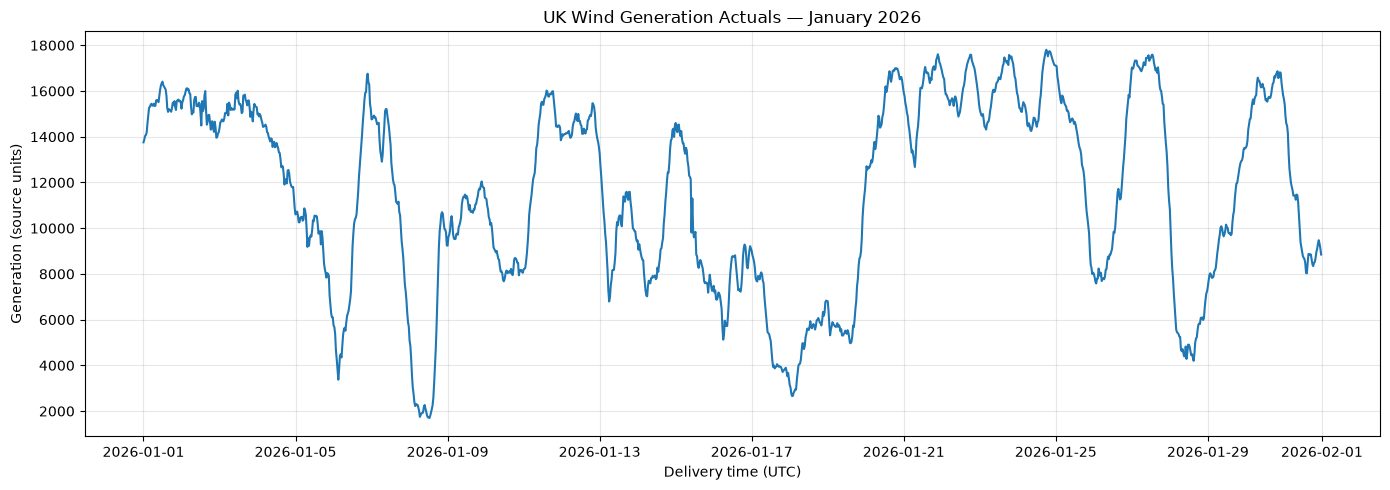

In [21]:
plt.figure(figsize=(14, 5))
plt.plot(actuals["startTime"], actuals["generation"])
plt.title("UK Wind Generation Actuals — January 2026")
plt.xlabel("Delivery time (UTC)")
plt.ylabel("Generation (source units)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

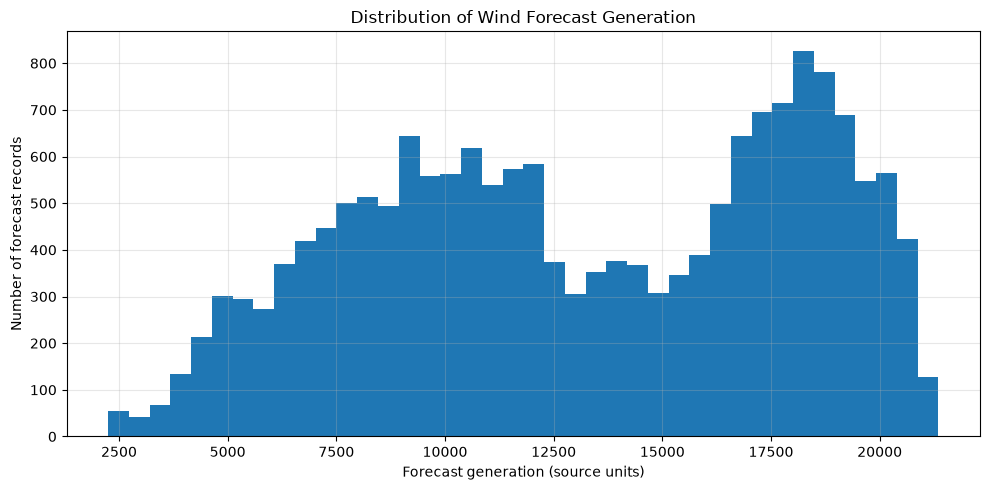

In [22]:
plt.figure(figsize=(10, 5))
plt.hist(forecasts["generation"].dropna(), bins=40)
plt.title("Distribution of Wind Forecast Generation")
plt.xlabel("Forecast generation (source units)")
plt.ylabel("Number of forecast records")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

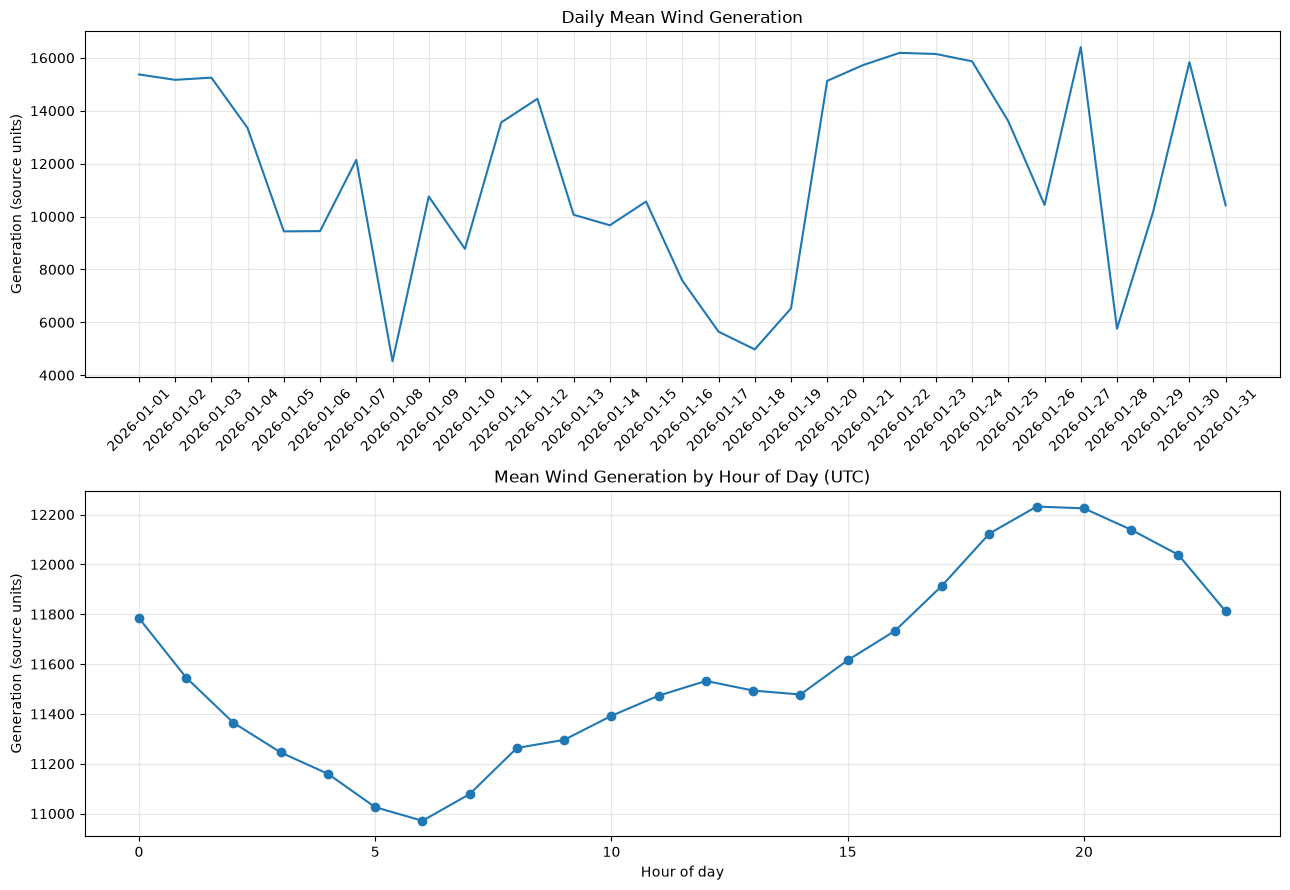

In [23]:
actuals["delivery_date"] = actuals["startTime"].dt.date
actuals["hour_utc"] = actuals["startTime"].dt.hour

daily_actuals = (
    actuals.groupby("delivery_date")["generation"]
    .agg(["mean", "min", "max"])
)

hourly_actuals = (
    actuals.groupby("hour_utc")["generation"]
    .mean()
)

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

axes[0].plot(daily_actuals.index.astype(str), daily_actuals["mean"])
axes[0].set_title("Daily Mean Wind Generation")
axes[0].set_ylabel("Generation (source units)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(True, alpha=0.3)

axes[1].plot(hourly_actuals.index, hourly_actuals.values, marker="o")
axes[1].set_title("Mean Wind Generation by Hour of Day (UTC)")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Generation (source units)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
actuals_jan = actuals[
    (actuals["startTime"] >= period_start)
    & (actuals["startTime"] < period_end)
].copy()

# Each hourly value is the mean of its two half-hourly generation values.
actuals_hourly = (
    actuals_jan.set_index("startTime")["generation"]
    .resample("1h")
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "actual_generation",
        "count": "half_hour_records",
    })
)

# Require both half-hour periods for a complete hourly observation.
actuals_hourly.loc[
    actuals_hourly["half_hour_records"] != 2,
    "actual_generation",
] = np.nan

actuals_hourly = actuals_hourly.reset_index()

display(actuals_hourly.head())
print("Hourly actual records:", len(actuals_hourly))
print(
    "Incomplete hourly actuals:",
    actuals_hourly["actual_generation"].isna().sum(),
)

,startTime,actual_generation,half_hour_records
0,2026-01-01 00:00:00+00:00,13814.5,2
1,2026-01-01 01:00:00+00:00,14056.5,2
2,2026-01-01 02:00:00+00:00,14380.0,2
3,2026-01-01 03:00:00+00:00,15103.0,2
4,2026-01-01 04:00:00+00:00,15349.5,2


Hourly actual records: 744
Incomplete hourly actuals: 0


In [25]:
# PROVISIONAL analytical assumption:
# Select the latest forecast published at least 24 hours before
# the start of its delivery hour.
#
# This is a configurable benchmark, NOT a verified market cutoff.
DECISION_LEAD_HOURS = 24

forecasts_jan = forecasts[
    (forecasts["startTime"] >= period_start)
    & (forecasts["startTime"] < period_end)
].copy()

forecasts_jan["decision_cutoff"] = (
    forecasts_jan["startTime"]
    - pd.Timedelta(hours=DECISION_LEAD_HOURS)
)

eligible_forecasts = forecasts_jan[
    forecasts_jan["publishTime"] <= forecasts_jan["decision_cutoff"]
].copy()

print("Forecast records in January:", len(forecasts_jan))
print("Eligible forecasts at selected cutoff:", len(eligible_forecasts))
print("Delivery hours with eligible forecasts:",
      eligible_forecasts["startTime"].nunique())

Forecast records in January: 17536
Eligible forecasts at selected cutoff: 7983
Delivery hours with eligible forecasts: 717


In [26]:
selected_forecasts = (
    eligible_forecasts
    .sort_values(["startTime", "publishTime"])
    .drop_duplicates(subset=["startTime"], keep="last")
    [["startTime", "publishTime", "generation"]]
    .rename(columns={
        "generation": "forecast_generation",
        "publishTime": "selected_publishTime",
    })
)

comparison = actuals_hourly.merge(
    selected_forecasts,
    on="startTime",
    how="left",
    validate="one_to_one",
)

comparison["forecast_lead_hours"] = (
    comparison["startTime"] - comparison["selected_publishTime"]
).dt.total_seconds() / 3600

comparison["forecast_error"] = (
    comparison["forecast_generation"] - comparison["actual_generation"]
)

comparison["absolute_error"] = comparison["forecast_error"].abs()

display(comparison.head(10))

print("Hourly actual rows:", len(actuals_hourly))
print("Matched forecast rows:",
      comparison["forecast_generation"].notna().sum())
print("Rows without an eligible forecast:",
      comparison["forecast_generation"].isna().sum())

,startTime,actual_generation,half_hour_records,selected_publishTime,forecast_generation,forecast_lead_hours,forecast_error,absolute_error
0,2026-01-01 00:00:00+00:00,13814.5,2,NaT,NaN,NaN,NaN,NaN
1,2026-01-01 01:00:00+00:00,14056.5,2,NaT,NaN,NaN,NaN,NaN
2,2026-01-01 02:00:00+00:00,14380.0,2,NaT,NaN,NaN,NaN,NaN
3,2026-01-01 03:00:00+00:00,15103.0,2,NaT,NaN,NaN,NaN,NaN
4,2026-01-01 04:00:00+00:00,15349.5,2,NaT,NaN,NaN,NaN,NaN
5,2026-01-01 05:00:00+00:00,15402.5,2,NaT,NaN,NaN,NaN,NaN
6,2026-01-01 06:00:00+00:00,15404.0,2,NaT,NaN,NaN,NaN,NaN
7,2026-01-01 07:00:00+00:00,15350.5,2,NaT,NaN,NaN,NaN,NaN
8,2026-01-01 08:00:00+00:00,15598.5,2,NaT,NaN,NaN,NaN,NaN
9,2026-01-01 09:00:00+00:00,15534.5,2,NaT,NaN,NaN,NaN,NaN


Hourly actual rows: 744
Matched forecast rows: 717
Rows without an eligible forecast: 27


In [27]:
evaluation = comparison.dropna(
    subset=["actual_generation", "forecast_generation"]
).copy()

error = (
    evaluation["forecast_generation"]
    - evaluation["actual_generation"]
)

mae = error.abs().mean()
rmse = np.sqrt((error ** 2).mean())
bias = error.mean()

# MAPE can become unstable when actual generation is zero or very small.
# Use only observations whose actual generation is safely above zero.
mape_mask = evaluation["actual_generation"].abs() > 1e-9
mape = (
    error[mape_mask].abs()
    / evaluation.loc[mape_mask, "actual_generation"].abs()
).mean() * 100

accuracy_metrics = pd.DataFrame({
    "metric": [
        "Matched hourly observations",
        "Mean Absolute Error (MAE)",
        "Root Mean Squared Error (RMSE)",
        "Mean Error / Bias",
        "Mean Absolute Percentage Error (MAPE)",
    ],
    "value": [
        len(evaluation),
        mae,
        rmse,
        bias,
        mape,
    ],
})

display(accuracy_metrics)

print("Bias interpretation:")
if bias > 0:
    print("Forecasts over-predict actual generation on average.")
elif bias < 0:
    print("Forecasts under-predict actual generation on average.")
else:
    print("Mean forecast error is approximately zero.")

,metric,value
0,Matched hourly observations,717.00
1,Mean Absolute Error (MAE),1984.92
2,Root Mean Squared Error (RMSE),2438.06
3,Mean Error / Bias,1767.49
4,Mean Absolute Percentage Error (MAPE),20.48


Bias interpretation:
Forecasts over-predict actual generation on average.


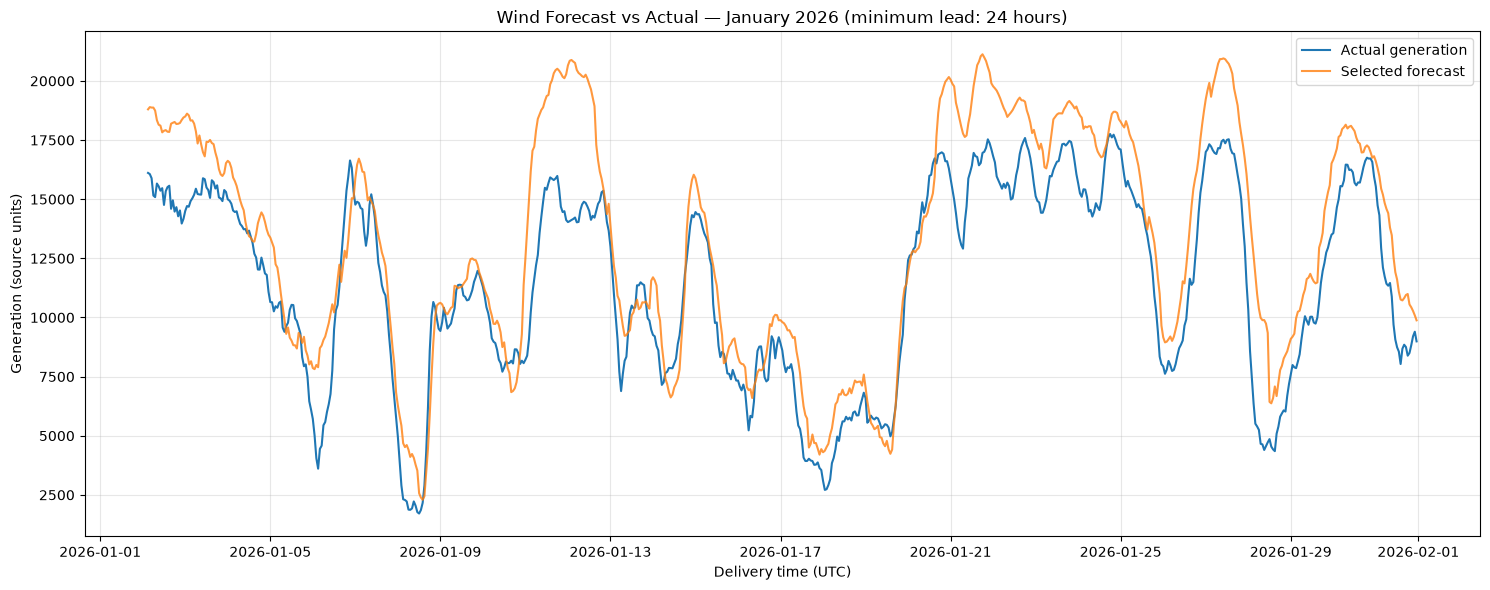

In [28]:
plt.figure(figsize=(15, 6))

plt.plot(
    evaluation["startTime"],
    evaluation["actual_generation"],
    label="Actual generation",
)

plt.plot(
    evaluation["startTime"],
    evaluation["forecast_generation"],
    label="Selected forecast",
    alpha=0.8,
)

plt.title(
    f"Wind Forecast vs Actual — January 2026 "
    f"(minimum lead: {DECISION_LEAD_HOURS} hours)"
)
plt.xlabel("Delivery time (UTC)")
plt.ylabel("Generation (source units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

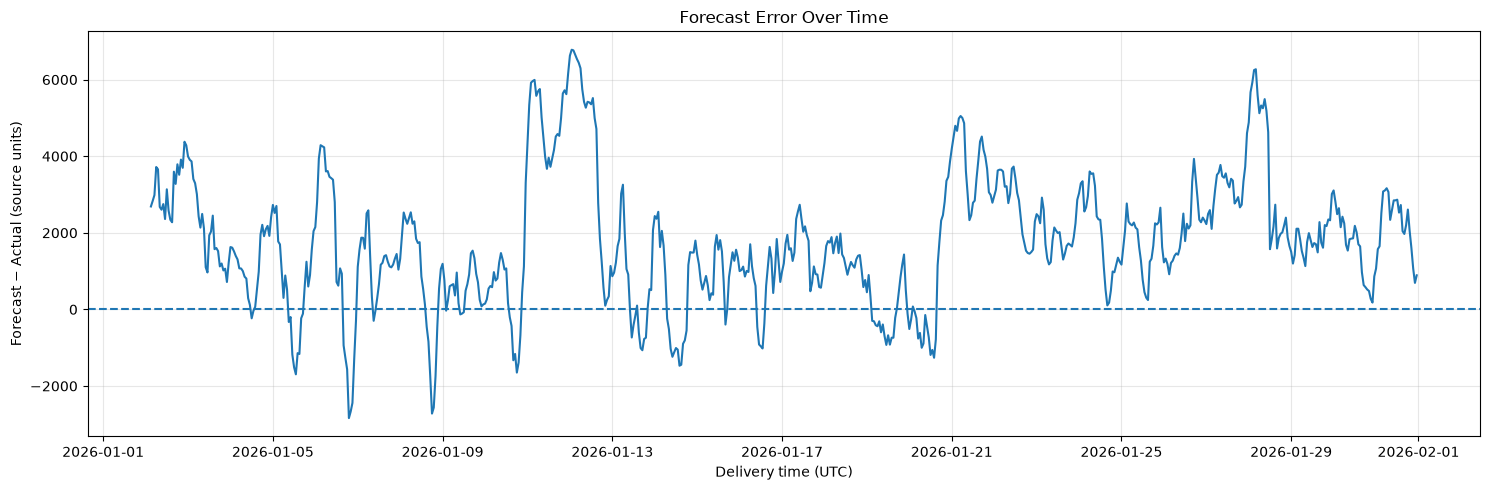

In [29]:
plt.figure(figsize=(15, 5))

plt.axhline(0, linestyle="--")
plt.plot(evaluation["startTime"], evaluation["forecast_error"])

plt.title("Forecast Error Over Time")
plt.xlabel("Delivery time (UTC)")
plt.ylabel("Forecast − Actual (source units)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
evaluation["delivery_date"] = evaluation["startTime"].dt.date
evaluation["hour_utc"] = evaluation["startTime"].dt.hour

daily_accuracy = (
    evaluation.groupby("delivery_date")
    .agg(
        observations=("forecast_error", "count"),
        mae=("absolute_error", "mean"),
        rmse=("forecast_error", lambda x: np.sqrt((x ** 2).mean())),
        bias=("forecast_error", "mean"),
    )
    .reset_index()
)

display(daily_accuracy)

,delivery_date,observations,mae,rmse,bias
0,2026-01-02,21,3192.79,3254.60,3192.79
1,2026-01-03,24,2090.17,2318.73,2090.17
2,2026-01-04,24,1216.00,1417.89,1193.46
3,2026-01-05,24,1192.27,1418.93,561.69
4,2026-01-06,24,2442.23,2755.80,1333.15
5,2026-01-07,24,1239.06,1383.37,1211.35
6,2026-01-08,24,1616.81,1801.98,739.98
7,2026-01-09,24,600.06,753.00,571.23
8,2026-01-10,24,944.27,1149.24,374.23
9,2026-01-11,24,4968.44,5033.41,4968.44


,hour_utc,observations,mae,rmse,bias
0,0,29,2135.50,2602.70,2100.22
1,1,29,2311.22,2806.90,2292.91
2,2,29,2433.28,2981.52,2431.03
3,3,30,2434.23,2970.83,2410.73
4,4,30,2473.40,2986.44,2437.60
5,5,30,2482.62,2942.18,2404.32
6,6,30,2416.50,2902.88,2346.27
7,7,30,2248.48,2765.36,2145.02
8,8,30,2071.32,2531.00,1937.85
9,9,30,2024.62,2481.21,1878.05


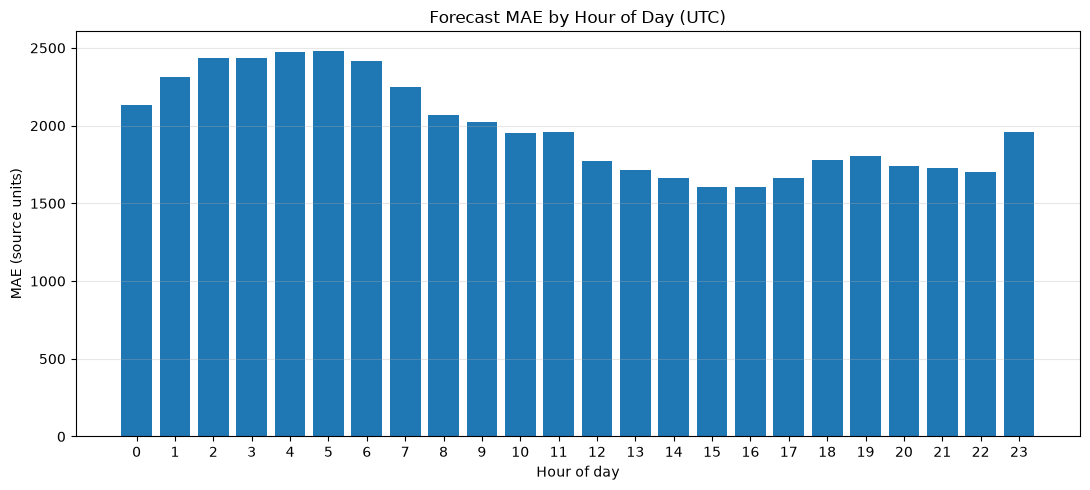

In [31]:
hourly_accuracy = (
    evaluation.groupby("hour_utc")
    .agg(
        observations=("forecast_error", "count"),
        mae=("absolute_error", "mean"),
        rmse=("forecast_error", lambda x: np.sqrt((x ** 2).mean())),
        bias=("forecast_error", "mean"),
    )
    .reset_index()
)

display(hourly_accuracy)

plt.figure(figsize=(11, 5))
plt.bar(hourly_accuracy["hour_utc"], hourly_accuracy["mae"])
plt.title("Forecast MAE by Hour of Day (UTC)")
plt.xlabel("Hour of day")
plt.ylabel("MAE (source units)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
lead_time_results = []

for lead_hours in [48, 24, 12, 6, 1]:
    eligible = forecasts_jan[
        forecasts_jan["publishTime"]
        <= forecasts_jan["startTime"] - pd.Timedelta(hours=lead_hours)
    ].copy()

    selected = (
        eligible.sort_values(["startTime", "publishTime"])
        .drop_duplicates("startTime", keep="last")
        [["startTime", "generation"]]
        .rename(columns={"generation": "forecast_generation"})
    )

    test = actuals_hourly.merge(
        selected,
        on="startTime",
        how="inner",
        validate="one_to_one",
    ).dropna(subset=["actual_generation", "forecast_generation"])

    errors = test["forecast_generation"] - test["actual_generation"]

    lead_time_results.append({
        "minimum_lead_hours": lead_hours,
        "matched_hours": len(test),
        "MAE": errors.abs().mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
        "bias": errors.mean(),
    })

lead_time_comparison = pd.DataFrame(lead_time_results)
display(lead_time_comparison.sort_values("minimum_lead_hours", ascending=False))

,minimum_lead_hours,matched_hours,MAE,RMSE,bias
0,48,551,2328.59,2912.65,1773.65
1,24,717,1984.92,2438.06,1767.49
2,12,729,1859.76,2329.42,1652.77
3,6,735,1847.21,2314.23,1647.35
4,1,740,1784.90,2269.40,1574.28


In [33]:
dashboard_kpis = {
    "period": "January 2026",
    "actual_half_hour_records": int(len(actuals_jan)),
    "expected_half_hour_records": int(len(expected_half_hourly)),
    "actual_hourly_records": int(len(actuals_hourly)),
    "matched_forecast_hours": int(len(evaluation)),
    "unmatched_actual_hours": int(
        comparison["forecast_generation"].isna().sum()
    ),
    "forecast_minimum_lead_hours": DECISION_LEAD_HOURS,
    "mae": float(mae) if pd.notna(mae) else None,
    "rmse": float(rmse) if pd.notna(rmse) else None,
    "bias": float(bias) if pd.notna(bias) else None,
    "mape_percent": float(mape) if pd.notna(mape) else None,
}

display(pd.DataFrame(
    dashboard_kpis.items(),
    columns=["KPI", "Value"],
))

,KPI,Value
0,period,January 2026
1,actual_half_hour_records,1488
2,expected_half_hour_records,1488
3,actual_hourly_records,744
4,matched_forecast_hours,717
5,unmatched_actual_hours,27
6,forecast_minimum_lead_hours,24
7,mae,1984.92
8,rmse,2438.06
9,bias,1767.49


In [34]:
forecast_actual_chart = evaluation[
    [
        "startTime",
        "actual_generation",
        "forecast_generation",
        "forecast_error",
        "absolute_error",
        "forecast_lead_hours",
    ]
].copy()

forecast_actual_chart["startTime"] = (
    forecast_actual_chart["startTime"].astype(str)
)

daily_chart = daily_accuracy.copy()
daily_chart["delivery_date"] = daily_chart["delivery_date"].astype(str)

hourly_chart = hourly_accuracy.copy()

print("Forecast vs actual chart data:")
display(forecast_actual_chart.head())

print("Daily accuracy chart data:")
display(daily_chart.head())

print("Hourly accuracy chart data:")
display(hourly_chart.head())

Forecast vs actual chart data:


,startTime,actual_generation,forecast_generation,forecast_error,absolute_error,forecast_lead_hours
27,2026-01-02 03:00:00+00:00,16110.5,18798.0,2687.5,2687.5,24.5
28,2026-01-02 04:00:00+00:00,16061.0,18892.0,2831.0,2831.0,25.5
29,2026-01-02 05:00:00+00:00,15888.0,18873.0,2985.0,2985.0,24.5
30,2026-01-02 06:00:00+00:00,15154.0,18872.0,3718.0,3718.0,25.5
31,2026-01-02 07:00:00+00:00,15088.0,18746.0,3658.0,3658.0,26.5


Daily accuracy chart data:


,delivery_date,observations,mae,rmse,bias
0,2026-01-02,21,3192.79,3254.60,3192.79
1,2026-01-03,24,2090.17,2318.73,2090.17
2,2026-01-04,24,1216.00,1417.89,1193.46
3,2026-01-05,24,1192.27,1418.93,561.69
4,2026-01-06,24,2442.23,2755.80,1333.15


Hourly accuracy chart data:


,hour_utc,observations,mae,rmse,bias
0,0,29,2135.50,2602.70,2100.22
1,1,29,2311.22,2806.90,2292.91
2,2,29,2433.28,2981.52,2431.03
3,3,30,2434.23,2970.83,2410.73
4,4,30,2473.40,2986.44,2437.60


In [35]:
dashboard_spec = {
    "filters": [
        "Delivery date range",
        "Minimum forecast lead time",
    ],
    "kpis": [
        "Matched forecast hours",
        "MAE",
        "RMSE",
        "Forecast bias",
        "MAPE",
    ],
    "visualizations": [
        "Hourly forecast vs actual time series",
        "Forecast error over time",
        "Daily accuracy trend",
        "MAE by hour of day",
        "Accuracy by forecast lead time",
    ],
    "data_scope": "UK national wind generation, January 2026",
    "forecast_policy": (
        "Latest forecast published at or before the configured "
        "delivery-time cutoff"
    ),
    "limitations": [
        "Forecast cutoff is an analytical assumption until verified.",
        "Coverage is limited to the supplied data.",
        "Accuracy results apply only to matched observations.",
    ],
}

print(json.dumps(dashboard_spec, indent=2))

{
  "filters": [
    "Delivery date range",
    "Minimum forecast lead time"
  ],
  "kpis": [
    "Matched forecast hours",
    "MAE",
    "RMSE",
    "Forecast bias",
    "MAPE"
  ],
  "visualizations": [
    "Hourly forecast vs actual time series",
    "Forecast error over time",
    "Daily accuracy trend",
    "MAE by hour of day",
    "Accuracy by forecast lead time"
  ],
  "data_scope": "UK national wind generation, January 2026",
  "forecast_policy": "Latest forecast published at or before the configured delivery-time cutoff",
  "limitations": [
    "Forecast cutoff is an analytical assumption until verified.",
    "Coverage is limited to the supplied data.",
    "Accuracy results apply only to matched observations."
  ]
}


In [36]:
with open(OUTPUT_DIR / "dashboard_kpis.json", "w", encoding="utf-8") as f:
    json.dump(dashboard_kpis, f, indent=2, allow_nan=False)

with open(OUTPUT_DIR / "dashboard_spec.json", "w", encoding="utf-8") as f:
    json.dump(dashboard_spec, f, indent=2)

print("KPI and dashboard specification JSON files exported.")

KPI and dashboard specification JSON files exported.


In [37]:
final_report = {
    "source_rows": {
        "actuals": int(len(actuals_raw)),
        "forecasts": int(len(forecasts_raw)),
    },
    "quality": {
        "actual_invalid_timestamps": int(actuals["startTime"].isna().sum()),
        "forecast_invalid_delivery_timestamps": int(
            forecasts["startTime"].isna().sum()
        ),
        "forecast_invalid_publication_timestamps": int(
            forecasts["publishTime"].isna().sum()
        ),
        "actual_duplicate_delivery_timestamps": int(
            actuals["startTime"].duplicated().sum()
        ),
        "forecast_duplicate_delivery_publication_pairs": int(
            forecasts.duplicated(["startTime", "publishTime"]).sum()
        ),
    },
    "evaluation": {
        "decision_lead_hours": DECISION_LEAD_HOURS,
        "matched_observations": int(len(evaluation)),
        "mae": float(mae) if pd.notna(mae) else None,
        "rmse": float(rmse) if pd.notna(rmse) else None,
        "bias": float(bias) if pd.notna(bias) else None,
        "mape_percent": float(mape) if pd.notna(mape) else None,
    },
}

with open(
    OUTPUT_DIR / "final_validation_report.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(final_report, f, indent=2, allow_nan=False)

display(pd.json_normalize(final_report, sep="_").T)
print("Final report saved.")

,0
source_rows_actuals,1488.00
source_rows_forecasts,17536.00
quality_actual_invalid_timestamps,0.00
quality_forecast_invalid_delivery_timestamps,0.00
quality_forecast_invalid_publication_timestamps,0.00
quality_actual_duplicate_delivery_timestamps,0.00
quality_forecast_duplicate_delivery_publication_pairs,0.00
evaluation_decision_lead_hours,24.00
evaluation_matched_observations,717.00
evaluation_mae,1984.92


Final report saved.


Forecast error distribution
---------------------------
Observations: 717
Mean error (bias): 1,767.49
Median error: 1,628.00
Standard deviation: 1,680.50
Skewness: 0.403
Excess kurtosis: 0.433
RMSE / MAE ratio: 1.228


C:\Users\dikid\AppData\Local\Temp\ipykernel_22136\3590300882.py:25: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(errors, vert=False)


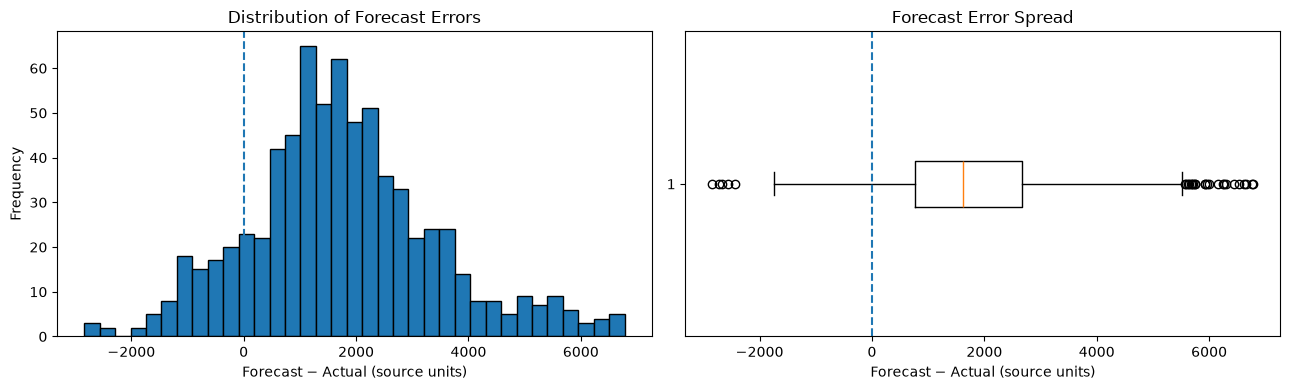

D'Agostino-Pearson normality test statistic: 22.717
p-value: 1.16699e-05
Evidence against a normal error distribution at the 5% level.


In [39]:

# VALIDATION 1: Forecast-error distribution

errors = (
    evaluation["forecast_generation"] - evaluation["actual_generation"]
).dropna()

print("Forecast error distribution")
print("---------------------------")
print(f"Observations: {len(errors)}")
print(f"Mean error (bias): {errors.mean():,.2f}")
print(f"Median error: {errors.median():,.2f}")
print(f"Standard deviation: {errors.std():,.2f}")
print(f"Skewness: {errors.skew():.3f}")
print(f"Excess kurtosis: {errors.kurtosis():.3f}")
print(f"RMSE / MAE ratio: {(np.sqrt((errors**2).mean()) / errors.abs().mean()):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(errors, bins=35, edgecolor="black")
axes[0].axvline(0, linestyle="--")
axes[0].set_title("Distribution of Forecast Errors")
axes[0].set_xlabel("Forecast − Actual (source units)")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(errors, vert=False)
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Forecast Error Spread")
axes[1].set_xlabel("Forecast − Actual (source units)")

plt.tight_layout()
plt.show()

# Optional formal normality test.
# A significant p-value is evidence against normality, not proof of a specific alternative.
try:
    from scipy.stats import normaltest

    if len(errors) >= 8:
        statistic, p_value = normaltest(errors)
        print(f"D'Agostino-Pearson normality test statistic: {statistic:.3f}")
        print(f"p-value: {p_value:.6g}")
        if p_value < 0.05:
            print("Evidence against a normal error distribution at the 5% level.")
        else:
            print("Insufficient evidence to reject normality at the 5% level.")
    else:
        print("Too few observations for this normality test.")
except ImportError:
    print("SciPy is unavailable; distribution plots and descriptive statistics are shown.")


In [40]:

# VALIDATION 2: Diagnose unmatched hours under the 24-hour cutoff

unmatched = comparison[
    comparison["forecast_generation"].isna()
][["startTime", "actual_generation"]].copy()

# Count all forecast records for each unmatched delivery hour,
# including forecasts that were published too late for the selected cutoff.
all_forecast_counts = forecasts_jan.groupby("startTime").size()
latest_publish = forecasts_jan.groupby("startTime")["publishTime"].max()

unmatched["all_forecast_records"] = (
    unmatched["startTime"].map(all_forecast_counts).fillna(0).astype(int)
)
unmatched["latest_available_publication"] = unmatched["startTime"].map(
    latest_publish
)
unmatched["latest_lead_hours"] = (
    unmatched["startTime"] - unmatched["latest_available_publication"]
).dt.total_seconds() / 3600

unmatched["diagnosis"] = np.select(
    [
        unmatched["all_forecast_records"].eq(0),
        unmatched["latest_lead_hours"].lt(24),
    ],
    [
        "No forecast record for delivery hour",
        "Forecast exists, but none meets 24-hour cutoff",
    ],
    default="Investigate publication timestamps or selection logic",
)

display(unmatched.sort_values("startTime").to_string(index=False))
print("\nDiagnosis counts:")
display(unmatched["diagnosis"].value_counts().to_frame("hours"))

print("\nUnmatched hours by delivery date:")
display(
    unmatched.assign(delivery_date=unmatched["startTime"].dt.date)
    .groupby("delivery_date")
    .size()
    .rename("unmatched_hours")
    .to_frame()
)


'                startTime  actual_generation  all_forecast_records latest_available_publication  latest_lead_hours                                      diagnosis\n2026-01-01 00:00:00+00:00            13814.5                     8    2026-01-01 22:30:00+00:00              -22.5 Forecast exists, but none meets 24-hour cutoff\n2026-01-01 01:00:00+00:00            14056.5                     8    2026-01-01 22:30:00+00:00              -21.5 Forecast exists, but none meets 24-hour cutoff\n2026-01-01 02:00:00+00:00            14380.0                     8    2026-01-01 22:30:00+00:00              -20.5 Forecast exists, but none meets 24-hour cutoff\n2026-01-01 03:00:00+00:00            15103.0                     8    2026-01-01 22:30:00+00:00              -19.5 Forecast exists, but none meets 24-hour cutoff\n2026-01-01 04:00:00+00:00            15349.5                     8    2026-01-01 22:30:00+00:00              -18.5 Forecast exists, but none meets 24-hour cutoff\n2026-01-01 05:00:00+0


Diagnosis counts:


,hours
diagnosis,
"Forecast exists, but none meets 24-hour cutoff",27



Unmatched hours by delivery date:


,unmatched_hours
delivery_date,
2026-01-01,24
2026-01-02,3


In [41]:

# VALIDATION 3: Percentage-metric reliability

metric_df = evaluation[
    ["actual_generation", "forecast_generation"]
].dropna().copy()

metric_df["error"] = (
    metric_df["forecast_generation"] - metric_df["actual_generation"]
)
metric_df["absolute_error"] = metric_df["error"].abs()

# WAPE: aggregate absolute error relative to aggregate actual generation.
actual_total = metric_df["actual_generation"].abs().sum()
wape = (
    metric_df["absolute_error"].sum() / actual_total * 100
    if actual_total > 0 else np.nan
)

# sMAPE: symmetric percentage error; undefined when both values sum to zero.
denominator = (
    metric_df["actual_generation"].abs()
    + metric_df["forecast_generation"].abs()
)
smape_mask = denominator > 1e-9
smape = (
    200 * metric_df.loc[smape_mask, "absolute_error"].div(
        denominator[smape_mask]
    )
).mean()

# Show sensitivity of MAPE to a practical minimum actual-generation threshold.
mape_threshold_results = []
for threshold in [1e-9, 100, 500, 1000, 2000]:
    mask = metric_df["actual_generation"].abs() > threshold
    threshold_mape = (
        (
            metric_df.loc[mask, "absolute_error"]
            / metric_df.loc[mask, "actual_generation"].abs()
        ).mean() * 100
        if mask.any() else np.nan
    )
    mape_threshold_results.append({
        "minimum_abs_actual": threshold,
        "observations_used": int(mask.sum()),
        "observations_excluded": int((~mask).sum()),
        "MAPE_percent": threshold_mape,
    })

print(f"WAPE: {wape:.2f}%")
print(f"sMAPE: {smape:.2f}%")
print("\nMAPE sensitivity to minimum actual-generation threshold:")
display(pd.DataFrame(mape_threshold_results))

print("\nActual generation range in evaluation set:")
print(metric_df["actual_generation"].describe())


WAPE: 17.36%
sMAPE: 17.50%

MAPE sensitivity to minimum actual-generation threshold:


,minimum_abs_actual,observations_used,observations_excluded,MAPE_percent
0,1.00e-09,717,0,20.48
1,1.00e+02,717,0,20.48
2,5.00e+02,717,0,20.48
3,1.00e+03,717,0,20.48
4,2.00e+03,711,6,19.88



Actual generation range in evaluation set:
count      717.00
mean     11436.85
std       4163.12
min       1711.50
25%       8135.00
50%      11641.50
75%      15088.00
max      17755.50
Name: actual_generation, dtype: float64


In [42]:

# VALIDATION 4: Coverage and apples-to-apples cutoff comparison

cutoffs = [48, 24, 12, 6, 1]
selected_by_cutoff = {}
coverage_rows = []

for lead_hours in cutoffs:
    eligible = forecasts_jan[
        forecasts_jan["publishTime"]
        <= forecasts_jan["startTime"] - pd.Timedelta(hours=lead_hours)
    ].copy()

    selected = (
        eligible.sort_values(["startTime", "publishTime"])
        .drop_duplicates("startTime", keep="last")
        [["startTime", "generation"]]
        .rename(columns={"generation": f"forecast_{lead_hours}h"})
    )

    selected_by_cutoff[lead_hours] = selected.set_index("startTime")[
        f"forecast_{lead_hours}h"
    ]

    coverage_rows.append({
        "minimum_lead_hours": lead_hours,
        "matched_hours": int(
            actuals_hourly["startTime"].isin(selected["startTime"]).sum()
        ),
        "coverage_percent": (
            actuals_hourly["startTime"].isin(selected["startTime"]).mean() * 100
        ),
    })

print("Coverage by cutoff:")
display(pd.DataFrame(coverage_rows))

# Keep only delivery hours that have an eligible forecast at every cutoff.
paired = actuals_hourly.set_index("startTime")[["actual_generation"]].copy()

for lead_hours, series in selected_by_cutoff.items():
    paired = paired.join(series, how="left")

forecast_columns = [f"forecast_{h}h" for h in cutoffs]
paired_common = paired.dropna(subset=["actual_generation"] + forecast_columns)

print("Common delivery hours available at every cutoff:", len(paired_common))

paired_results = []
for lead_hours in cutoffs:
    err = (
        paired_common[f"forecast_{lead_hours}h"]
        - paired_common["actual_generation"]
    )
    paired_results.append({
        "minimum_lead_hours": lead_hours,
        "common_hours": len(err),
        "MAE": err.abs().mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "bias": err.mean(),
    })

display(pd.DataFrame(paired_results).sort_values("minimum_lead_hours", ascending=False))


Coverage by cutoff:


,minimum_lead_hours,matched_hours,coverage_percent
0,48,551,74.06
1,24,717,96.37
2,12,729,97.98
3,6,735,98.79
4,1,740,99.46


Common delivery hours available at every cutoff: 551


,minimum_lead_hours,common_hours,MAE,RMSE,bias
0,48,551,2328.59,2912.65,1773.65
1,24,551,1915.63,2365.79,1641.80
2,12,551,1751.87,2208.60,1488.68
3,6,551,1692.65,2135.87,1437.56
4,1,551,1601.38,2050.28,1335.28


In [ ]:

# VALIDATION 5: Source assumptions and data scope

print("SOURCE AND METHODOLOGY CHECKLIST")
print("--------------------------------")

print("\n1. Timestamp strings in the original files:")
for label, df, col in [
    ("Actuals", actuals_raw, "startTime"),
    ("Forecast delivery", forecasts_raw, "startTime"),
    ("Forecast publication", forecasts_raw, "publishTime"),
]:
    print(f"\n{label} — examples:")
    print(df[col].dropna().astype(str).head(3).to_list())

print("\n2. Actual fuel types:")
display(actuals_raw["fuelType"].value_counts(dropna=False).to_frame("records"))

print("\n3. Generation ranges:")
display(pd.DataFrame({
    "actual_generation": actuals["generation"].describe(),
    "forecast_generation": forecasts["generation"].describe(),
}))

for item in assumptions_to_verify:
    print(f"- {item}")


SOURCE AND METHODOLOGY CHECKLIST
--------------------------------

1. Timestamp strings in the original files:

Actuals — examples:
['2026-01-31 23:30:00+00:00', '2026-01-31 23:00:00+00:00', '2026-01-31 22:30:00+00:00']

Forecast delivery — examples:
['2026-01-30 21:00:00+00:00', '2026-01-30 22:00:00+00:00', '2026-01-30 23:00:00+00:00']

Forecast publication — examples:
['2026-01-31 22:30:00+00:00', '2026-01-31 22:30:00+00:00', '2026-01-31 22:30:00+00:00']

2. Actual fuel types:


,records
fuelType,
WIND,1488



3. Generation ranges:


,actual_generation,forecast_generation
count,1488.00,17536.00
mean,11580.74,13167.61
std,4156.22,4871.96
min,1695.00,2250.00
25%,8197.50,9107.50
50%,12141.00,13030.00
75%,15265.50,17726.00
max,17805.00,21353.00



4. Checks requiring source documentation:
- Are actual and forecast generation expressed in the same unit?
- Does the source define generation values as MW, MWh, or another unit?
- Are timestamps explicitly UTC in the source documentation?
- Does startTime represent the beginning of the delivery interval?
- What forecast publication cutoff is required by the intended business use?
- Does the forecast dataset include publications from before January 1, 2026?


In [44]:

# VALIDATION 2B: Count forecasts eligible at least 24 hours ahead

cutoff = pd.Timedelta(hours=24)

forecast_rows = forecasts_jan.copy()
forecast_rows["eligible_24h"] = (
    forecast_rows["publishTime"]
    <= forecast_rows["startTime"] - cutoff
)

eligibility = (
    forecast_rows.groupby("startTime")
    .agg(
        total_forecast_records=("publishTime", "size"),
        eligible_forecast_records=("eligible_24h", "sum"),
        earliest_publication=("publishTime", "min"),
        latest_publication=("publishTime", "max"),
    )
    .reset_index()
)

eligibility["has_24h_forecast"] = (
    eligibility["eligible_forecast_records"] > 0
)

print("Forecast records available at least 24 hours before delivery:")
display(
    eligibility[
        eligibility["startTime"].dt.date
        <= pd.Timestamp("2026-01-03").date()
    ].sort_values("startTime").to_string(index=False)
)

print("\nEligible forecast coverage:")
print(eligibility["has_24h_forecast"].value_counts())


Forecast records available at least 24 hours before delivery:


'                startTime  total_forecast_records  eligible_forecast_records      earliest_publication        latest_publication  has_24h_forecast\n2026-01-01 00:00:00+00:00                       8                          0 2026-01-01 02:30:00+00:00 2026-01-01 22:30:00+00:00             False\n2026-01-01 01:00:00+00:00                       8                          0 2026-01-01 02:30:00+00:00 2026-01-01 22:30:00+00:00             False\n2026-01-01 02:00:00+00:00                       8                          0 2026-01-01 02:30:00+00:00 2026-01-01 22:30:00+00:00             False\n2026-01-01 03:00:00+00:00                       8                          0 2026-01-01 02:30:00+00:00 2026-01-01 22:30:00+00:00             False\n2026-01-01 04:00:00+00:00                       8                          0 2026-01-01 02:30:00+00:00 2026-01-01 22:30:00+00:00             False\n2026-01-01 05:00:00+00:00                       8                          0 2026-01-01 02:30:00+00:00 2026-01-


Eligible forecast coverage:
has_24h_forecast
True     717
False     27
Name: count, dtype: int64


In [45]:
print("Earliest publication:", forecasts_raw["publishTime"].min())
print("Latest publication:", forecasts_raw["publishTime"].max())

publication_times = pd.to_datetime(
    forecasts_raw["publishTime"], utc=True, errors="coerce"
)

print("Earliest parsed publication:", publication_times.min())
print(
    "Forecast records published before January 1:",
    (publication_times < pd.Timestamp("2026-01-01", tz="UTC")).sum()
)

Earliest publication: 2026-01-01 02:30:00+00:00
Latest publication: 2026-01-31 22:30:00+00:00
Earliest parsed publication: 2026-01-01 02:30:00+00:00
Forecast records published before January 1: 0
